# Matrix factorization with multiple seeds

This is the sequential version of
[the final parallel notebook](experiment_matrix_factorization_multiple_parallel_final.ipynb),
with the simple seed loop of `experiment_matrix_factorization_multiple.ipynb`.
Run all cells from the repository root or `MF`. Every method uses the same data
and starting factors within a seed. The three figures use arithmetic means
with terminal values retained.

Install in the notebook's Python environment if needed:
```python
%pip install numpy scipy matplotlib threadpoolctl galahad-optrove==5.5.3
```

For $U\in\mathbb{R}^{m\times r}$ and $V\in\mathbb{R}^{r\times n}$, minimize
$$F(U,V)=\tfrac12\|UV-M_{\mathrm{obs}}\|_F^2
 +\tfrac\alpha2(\|U\|_F^2+\|V\|_F^2)
 +\tfrac\beta2(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$
The last term is the **weighted penalty** plotted below. Nonnegativity is
penalized, not imposed by projection. Data use uniform factors plus Gaussian
noise; starting factors are Gaussian.

Reference: [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1),
Section 5.2 / Appendix E.2, Algorithm 1 and subproblem (2). Equation (28) is the
paper's objective; this notebook uses the weights above. Defaults, extra
comparisons and aggregation differ from the paper, so this is not an exact
reproduction of its figures.

| Paper figure | Input to the mean |
| --- | --- |
| 3: nonnegativity violation | `penalty` (weighted here) |
| 4: gradient norm | `grad_norm` |
| 6: objective residual | `func`, then subtract the shared reference |

Solver settings, seeds and initialization match the final parallel notebook.
Only execution is sequential; wall times will differ.

In [9]:
import sys
from pathlib import Path
from datetime import datetime
from time import perf_counter
import importlib.metadata
import platform
import pickle

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
sys.path.insert(0, str(MF_DIR.resolve()))

%reload_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits, threadpool_info
from galahad import glrt  # Load native libraries before limiting their threads.
from oracles_mat_fac import PositiveMatrixFactorization
from methods import gradient_method, mf_leapssn, mf_gladssn, cubic_newton_nonconvex_new
from utils_new import plot_figures, prepare_mean_histories

## Parameters

`gradient_iterations` and `number_of_iterations` are update budgets.
`grad_tol` stops a method once its full gradient norm is small enough; `None`
disables it. `success` means this target was reached; `iterations_exceeded`
means the budget ran out. Check other exit statuses before interpreting a curve.

`initial_lambda` initializes the LeAP/GLAd shift; GLAd scales it with
`||g||**p`. MINRES solves are inexact. LeAP/GLAd use fresh generalized Hessians;
the extra `gn_exponents` variants and LeAP (GN) use Gauss-Newton curvature.

The [cubic baseline](CUBIC_SUBPROBLEM.md) uses inexact GLRT subproblem solves,
independently of `initial_lambda`. Its cubic term is `H_k * ||s||**3 / 6`.
It accepts a nonpositive model change when `f(x+s) <= f(x)+model_change`;
rejection doubles `H_k`, acceptance halves it with floor `1e-5`.

Quick check: use `(m, n, r) = (6, 4, 2)`, seeds `[549, 498]`, 20 gradient
updates and 5 Newton updates. These are check settings, not the full experiment.

In [10]:
# Original recorded seeds (uncomment for the 20-seed experiment):
# seeds_to_try = [549, 498, 483, 33, 528, 989, 465, 344, 153, 867,
#                 107, 424, 998, 230, 996, 229, 725, 911, 418, 146]
seeds_to_try = [549]

# Data and objective
m, n, r = 50, 25, 4

noise = 0.2
alpha, beta = 0.01, 500.0
initial_factor_std = 0.05

# Iteration budgets and regularization
gradient_iterations = 25000
number_of_iterations = 2000
grad_tol = 1e-8  # Absolute outer gradient norm; None disables this tolerance.
initial_lambda = 10.0
lss_method = "minres"  # SciPy MINRES; GLRT keeps its compiled GALAHAD backend.
lss_tol = 1e-7
lss_maxiters = 800
gn_exponents = [0.2, 0.5]       # Additional exact/Gauss-Newton comparisons

# Additional nonconvex cubic baseline (independent of initial_lambda)
cubic_initial_H = 10.0
cubic_subproblem_tol = 1e-7  # Model-gradient residual relative to ||g||
cubic_glrt_max_iter = 6000  # Per-trial cap.
cubic_max_backtracks = 120

# Sequential execution and optional export
THREADS = 1
SAVE_FIGURES = False  # Save the three PDFs and run data under multiple_results/.

## Methods

Shared options keep the method list short. Every GLAd exponent uses the same
settings apart from `p`; GN pairs also change `use_gauss_newton`.

In [11]:
newton_options = dict(
    n_iters=number_of_iterations, grad_tol=grad_tol, H_0=initial_lambda,
    warnings=False, lss_tol=lss_tol, lss_maxiters=lss_maxiters,
    lss_method=lss_method, use_gauss_newton=False,
)
methods_to_run = {
    "Gradient Method": (gradient_method, dict(
        max_iter=gradient_iterations, grad_tol=grad_tol, warnings=False)),
    "LeAP-SSN": (mf_leapssn, newton_options),
}
for p in (0.2, 0.4, 0.5, 0.6, 0.8):
    methods_to_run[f"GLAd-SSN, p={p:g}"] = (mf_gladssn, dict(newton_options, p=p))
methods_to_run["Cubic Newton (GLRT)"] = (cubic_newton_nonconvex_new, dict(
    n_iters=number_of_iterations, grad_tol=grad_tol, H_0=cubic_initial_H,
    subproblem_tol=cubic_subproblem_tol, glrt_max_iter=cubic_glrt_max_iter,
    max_backtracks=cubic_max_backtracks, warnings=False,
))
for name in ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in gn_exponents]:
    solver, options = methods_to_run[name]
    methods_to_run[f"{name} (GN)"] = (solver, dict(options, use_gauss_newton=True))

## Run the seeds

The loop below runs one method at a time, then moves to the next seed. Random
draw order matches the parallel notebook, including the transpose used for
`V`. Computation uses float64 and `THREADS` numerical-library threads.

Runtime panels use each solver's cumulative wall time, excluding data creation
and plotting. BLAS is initialized before timing and limiting threads.
Whole-call times and environment details are also kept below.
An interrupted batch must be rerun before calculating the all-seed means.

In [12]:
experiment_config = dict(
    m=m, n=n, r=r, noise=noise, alpha=alpha, beta=beta,
    initial_factor_std=initial_factor_std,
    gradient_iterations=gradient_iterations, number_of_iterations=number_of_iterations,
    grad_tol=grad_tol, initial_lambda=initial_lambda,
    lss_method=lss_method, lss_tol=lss_tol, lss_maxiters=lss_maxiters,
    gn_exponents=list(gn_exponents), cubic_initial_H=cubic_initial_H,
    cubic_subproblem_tol=cubic_subproblem_tol, cubic_glrt_max_iter=cubic_glrt_max_iter,
    cubic_max_backtracks=cubic_max_backtracks,
)

run_metadata = dict(
    started_at=datetime.now().astimezone().isoformat(),
    python=platform.python_version(), platform=platform.platform(), processor=platform.processor(),
    packages={name: importlib.metadata.version(name) for name in
              ("numpy", "scipy", "matplotlib", "threadpoolctl", "galahad-optrove")},
    precision="float64", seeds=list(seeds_to_try), configuration=experiment_config,
    execution="sequential", threads=THREADS,
)
all_seeds_histories, all_seeds_statuses = {}, {}
all_seeds_cubic_diagnostics, all_seeds_timing = {}, {}
batch_complete = False
# Initialize BLAS/OpenMP before limiting all loaded libraries.
_ = np.zeros((2, 2)) @ np.zeros((2, 2))
batch_started = perf_counter()

with threadpool_limits(limits=THREADS):
    run_metadata["thread_pools"] = threadpool_info()
    for seed in seeds_to_try:
        print(f"Seed {seed} ({len(all_seeds_histories) + 1}/{len(seeds_to_try)})")
        rng = np.random.RandomState(seed)
        U_true = rng.rand(m, r)
        V_true = rng.rand(n, r).T
        M_obs = U_true @ V_true + noise * rng.randn(m, n)

        initial_values = initial_factor_std * rng.randn(m*r + n*r)
        U_0 = initial_values[:m*r].reshape(m, r)
        V_0 = initial_values[m*r:].reshape(n, r).T
        oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=alpha, beta=beta)
        x_0 = oracle.pack(U_0, V_0)

        histories, statuses, timings = {}, {}, {}
        for name, (solver, options) in methods_to_run.items():
            started = perf_counter()
            _, status, history = solver(oracle, x_0, **options)
            timings[name] = perf_counter() - started
            statuses[name] = status
            histories[name] = {key: np.asarray(history[key])
                               for key in ("func", "time", "grad_norm", "penalty")}
            if name == "Cubic Newton (GLRT)":
                all_seeds_cubic_diagnostics[seed] = {key: np.asarray(history[key]) for key in (
                    "hess_vec_calls", "glrt_iterations", "glrt_status",
                    "subproblem_relative_residual", "subproblem_calls", "H_k") if key in history}
            print(f"  {name}: {status}, ||g||={history['grad_norm'][-1]:.2e}, {timings[name]:.2f} s")

        all_seeds_histories[seed] = histories
        all_seeds_statuses[seed] = statuses
        all_seeds_timing[seed] = timings

batch_complete = True
run_metadata["batch_elapsed_seconds"] = perf_counter() - batch_started
print(f"Finished {len(all_seeds_histories)} seeds in {run_metadata['batch_elapsed_seconds']:.1f} s.")

Seed 549 (1/1)
  Gradient Method: iterations_exceeded, ||g||=1.22e-03, 3.99 s
  LeAP-SSN: success, 129 iters, ||g||=1.01e-09, 0.51 s
  GLAd-SSN, p=0.2: success, 261 iters, ||g||=2.17e-09, 1.32 s
  GLAd-SSN, p=0.4: success, 218 iters, ||g||=2.22e-09, 1.19 s
  GLAd-SSN, p=0.5: success, 208 iters, ||g||=2.09e-09, 1.23 s
  GLAd-SSN, p=0.6: success, 148 iters, ||g||=4.63e-10, 0.92 s
  GLAd-SSN, p=0.8: success, 231 iters, ||g||=9.48e-10, 1.34 s
  Cubic Newton (GLRT): success, 68 iters, ||g||=1.83e-09, 0.51 s
  LeAP-SSN (GN): numerical_stagnation, 831 iters, ||g||=7.47e-08, 6.53 s
  GLAd-SSN, p=0.2 (GN): numerical_stagnation, 856 iters, ||g||=6.41e-08, 7.10 s
  GLAd-SSN, p=0.5 (GN): numerical_stagnation, 895 iters, ||g||=6.73e-08, 6.58 s
Finished 1 seeds in 31.3 s.


## Arithmetic mean with terminal values retained

The three figures show objective residual, gradient norm and weighted penalty.
Every seed keeps equal weight, including failures. Stopped runs contribute
their actual final value. Runtime uses the latest observation on a shared time
grid; iterations use matching update counts. No interpolation or log averaging.

For a fixed method and $S$ seeds, let $q_{s,j}$ denote the recorded objective
$F_s(x_{s,j})$, gradient norm $\|\nabla F_s(x_{s,j})\|_2$, or weighted penalty
$P_s(x_{s,j})$. Let $t_{s,j}$ be the runtime and $K_s$ the last recorded
iteration, with the initial point at $j=0$. The means are

$$
\bar q_{\mathrm{iter}}(k)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,\min(k,K_s)},
$$

$$
\bar q_{\mathrm{time}}(t)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,j_s(t)},
\qquad
j_s(t)=\max\{j\in\{0,\ldots,K_s\}:t_{s,j}\le t\}.
$$

The shared time grid starts after every run has its first observation.
After seed $s$ ends, it contributes $q_{s,K_s}$; the denominator stays $S$.
For gradients this averages **norms**, not gradient vectors.

The objective panels display $\bar F-F_{\mathrm{ref}}$, where $F_{\mathrm{ref}}$
is the smallest recorded arithmetic mean across all plotted methods and both
grids, not a known optimum. Its axis is linear below
`mean_objective_zero_scale` (default `1e-8`), then logarithmic. Objective and
penalty curves end at each method's last recording. Penalty zeros and later rebounds are retained; its axis is
linear below `mean_penalty_zero_scale` (default `1e-5`), then logarithmic.

Gradient curves keep the existing cutoff: all seeds at or below
`mean_gradient_target`, otherwise the last recording. Terminal gradient plateaus
within 0.1% of each seed's final norm are hidden; set
`mean_gradient_flat_tail_rtol=None` to disable this display rule. It does not
certify convergence. Missed gradient targets remain listed below.

The gradient target defaults to this run's `grad_tol`. All three plots call
`plot_figures()` directly, using the original colors and layout; dashed lines
show GN variants. The full means and display cutoffs remain available in
`arithmetic_mean_summaries`. Axis limits below only zoom the view.

In [13]:
assert batch_complete, "Run all seeds before plotting."

# Same colors and order as the final arithmetic plots in the parallel notebook.
method_colors = {
    "Gradient Method": "#E8601C", "LeAP-SSN": "black",
    "GLAd-SSN, p=0.2": "#9B8AC4", "GLAd-SSN, p=0.4": "#88A5DD",
    "GLAd-SSN, p=0.5": "#8DCBE4", "GLAd-SSN, p=0.6": "#C2E3D2",
    "GLAd-SSN, p=0.8": "#DDECBF", "Cubic Newton (GLRT)": "#A97900",
}
plot_names = []
for name in ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in (0.2, 0.4, 0.5, 0.6, 0.8)]:
    plot_names.append(name)
    if name + " (GN)" in methods_to_run:
        plot_names.append(name + " (GN)")
plot_names += ["Cubic Newton (GLRT)", "Gradient Method"]
colors = [method_colors[name.removesuffix(" (GN)")] for name in plot_names]
line_styles = ["--" if name.endswith(" (GN)") else "-" for name in plot_names]
line_widths = [2.0] * len(plot_names)

mean_gradient_target = run_metadata["configuration"]["grad_tol"]
mean_gradient_flat_tail_rtol = 1e-3  # Display only; None keeps terminal plateaus.
mean_objective_zero_scale = 1e-8
mean_penalty_zero_scale = 1e-5
max_time = None  # E.g. 200 seconds to zoom.
max_iter = None  # E.g. 150 iterations to zoom.

arithmetic_mean_histories, arithmetic_mean_summaries = {}, {}
for measure in ("func", "grad_norm", "penalty"):
    prepared, summary = prepare_mean_histories(
        all_seeds_histories, plot_names, measure=measure,
        target=mean_gradient_target if measure == "grad_norm" else None,
        flat_tail_rtol=mean_gradient_flat_tail_rtol if measure == "grad_norm" else None,
    )
    arithmetic_mean_histories[measure] = prepared
    arithmetic_mean_summaries[measure] = summary

mean_objective_reference = min(
    np.min(values) for summary in arithmetic_mean_summaries["func"].values()
    for values in summary["means"].values()
)
for axis, summary in arithmetic_mean_summaries["grad_norm"].items():
    missed = [name for name, e in summary["endpoints"].items() if e["all_seeds_reached"] is False]
    trimmed = [name for name, e in summary["endpoints"].items() if e["flat_tail_trimmed"]]
    print(f"{axis}: gradient target missed:", ", ".join(missed) or "none")
    print(f"{axis}: terminal plateau hidden:", ", ".join(trimmed) or "none")

runtime: gradient target missed: LeAP-SSN (GN), GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.5 (GN), Gradient Method
runtime: terminal plateau hidden: none
iteration: gradient target missed: LeAP-SSN (GN), GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.5 (GN), Gradient Method
iteration: terminal plateau hidden: none


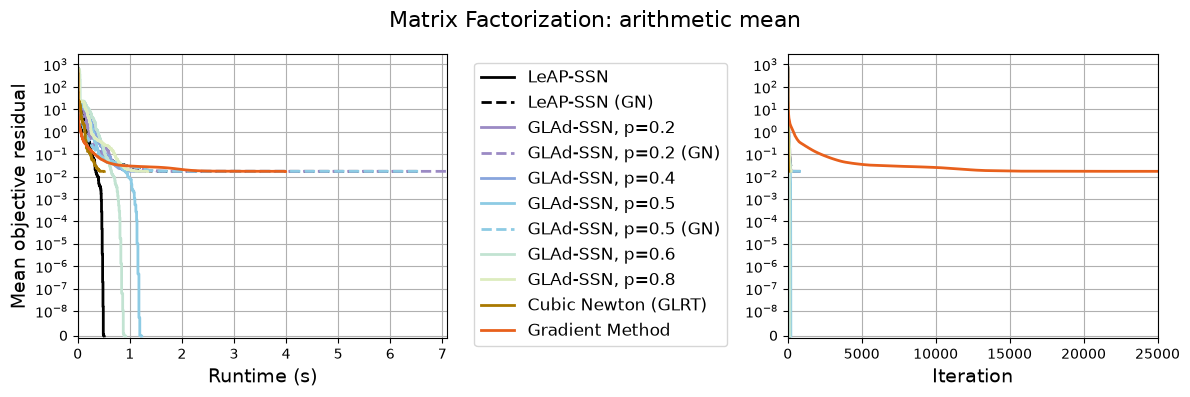

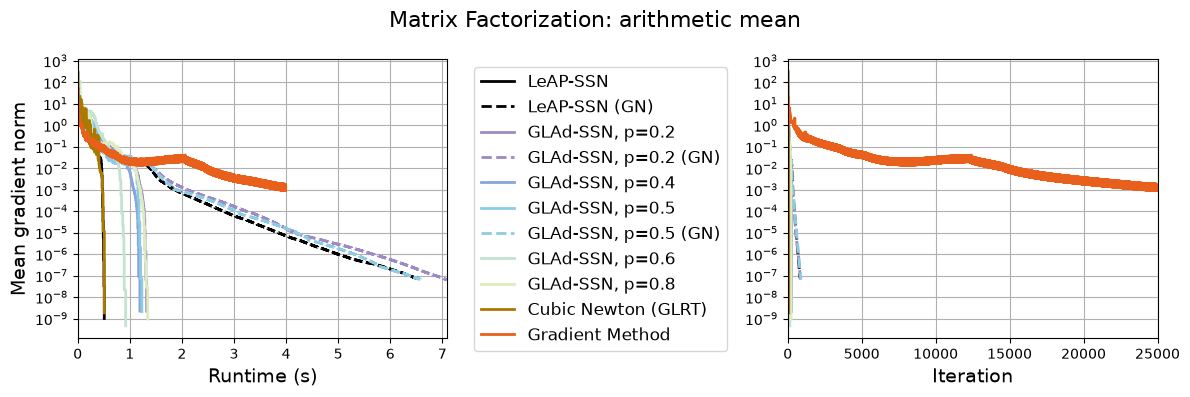

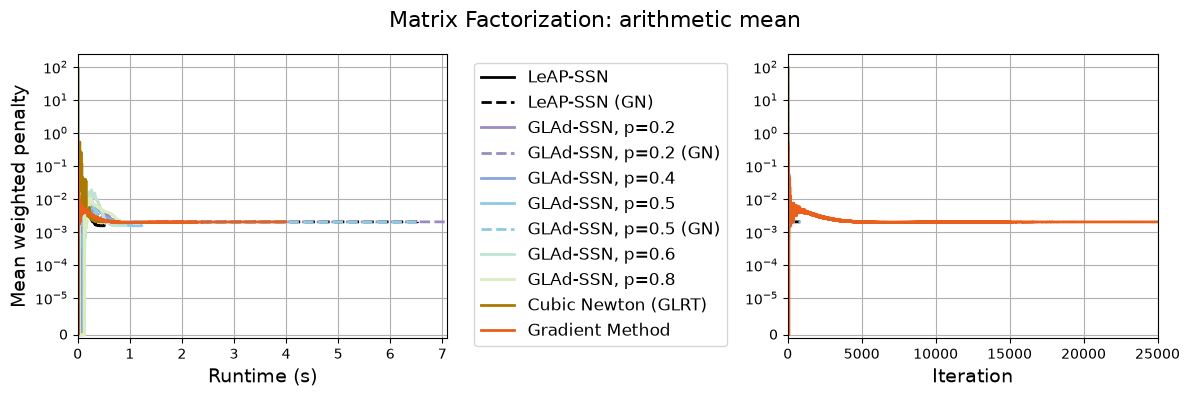

In [14]:
zero_scales = dict(func=mean_objective_zero_scale, grad_norm=1e-14, penalty=mean_penalty_zero_scale)
arithmetic_mean_figures = {}
for measure, reference, ylabel in [
    ("func", mean_objective_reference, "Mean objective residual"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean weighted penalty"),
]:
    prepared = arithmetic_mean_histories[measure]
    summary = arithmetic_mean_summaries[measure]
    limits = {}
    for axis, limit in [("runtime", max_time), ("iteration", max_iter)]:
        last_shown = max(e["x"] for e in summary[axis]["endpoints"].values())
        limits[axis] = limit if limit is not None else max(last_shown, 1e-12)
    note = f"All {len(all_seeds_histories)} seeds retained after exits, including failures. Dashed: Gauss-Newton."
    if measure == "grad_norm":
        note += (f"\nCutoff: all seeds <= {mean_gradient_target:g}, otherwise last recording."
                 if mean_gradient_target is not None else "\nCutoff: each method's last recording.")
        if mean_gradient_flat_tail_rtol is not None:
            note += f" Terminal plateaus hidden ({100 * mean_gradient_flat_tail_rtol:g}%; display only)."
    elif measure == "func":
        note += "\nReference: best observed mean across methods and both panels; not a known optimum."
    note += f"\nLinear below {zero_scales[measure]:g}, log above. Sequential wall times."
    # set note = '' if you want to remove the note from the figure.
    note = ''

    fig = plot_figures(
        list(prepared.values()), plot_names, n=n, m=m, mu_str=None,
        colors=colors, linewidths=line_widths, linestyles=line_styles,
        which_measure_1="runtime", which_measure_2="iteration",
        f_star=reference, threshold=None, zero_scale=zero_scales[measure],
        max_time=limits["runtime"], max_iter=limits["iteration"],
        xlabel="Runtime (s)", ylabel=ylabel,
        suptitle="Matrix Factorization: arithmetic mean",
        sharey=True, runtime_steps=True, verbose=False, note=note,
    )
    arithmetic_mean_figures[measure] = fig
    display(fig)
    plt.close(fig)

## Save the figures and data (optional)

Set `SAVE_FIGURES=True` to write the three PDFs and `results.pkl` into a new,
ignored `multiple_results/` folder. The data include individual histories,
solver statuses, cubic diagnostics, settings, environment details, full means
and displayed curves, so the plots can be recreated without rerunning solvers.

In [15]:
if SAVE_FIGURES:
    output_dir = MF_DIR / "multiple_results" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    for measure, filename in [("func", "mean_objective.pdf"), ("grad_norm", "mean_gradient.pdf"),
                              ("penalty", "mean_penalty.pdf")]:
        arithmetic_mean_figures[measure].savefig(output_dir / filename, bbox_inches="tight")
    results = dict(
        run_metadata=run_metadata, histories=all_seeds_histories, statuses=all_seeds_statuses,
        timings=all_seeds_timing, cubic_diagnostics=all_seeds_cubic_diagnostics,
        summaries=arithmetic_mean_summaries, plot_histories=arithmetic_mean_histories,
        plot_settings=dict(
            names=plot_names, colors=colors, linestyles=line_styles, linewidths=line_widths,
            objective_reference=float(mean_objective_reference), zero_scales=zero_scales,
            gradient_target=mean_gradient_target, gradient_flat_tail_rtol=mean_gradient_flat_tail_rtol,
            max_time=max_time, max_iter=max_iter,
        ),
    )
    with (output_dir / "results.pkl").open("wb") as result_file:
        pickle.dump(results, result_file)
    print("Saved figures and data to", output_dir)